# Multivariate Change Detection

*Section 6 — Change detection, notebook 5 of 5.* Previous: `04_map_to_image_change`. Next: `07_spectral_analysis/01_spectral_analysis_intro`.

**You will learn:**
- how to compare two images using all of their bands at once, with change vector analysis (CVA), iteratively reweighted slow feature analysis (IR-SFA) and iteratively reweighted multivariate alteration detection (IR-MAD) from `rsgispy.changedetect.imgchngmthds`;
- how to match the bands of two sensors (Landsat 5 TM and Landsat 8 OLI) and build an analysis mask where both images have data;
- how the change thresholds are chosen (Otsu or k-means) and what `apply_std` does;
- how to read the diagnostics the change functions return (the threshold, the number of changed pixels and, for IR-SFA and IR-MAD, the iterations and whether they converged), and what `mad_regularisation` does;
- how to plot the change distance histogram with `plot_img_histogram` and map the change distance, the binary change and the MAD variates with `create_map_panels`, and how to compare the results of the three methods.

**Before you start:** this notebook follows on from the image-to-image change in `03_image_to_image_change`, which compared a single index (NDVI). It creates its own masks, so it can be run on its own, but section 8 compares the results with the map-to-map change map of `02_map_to_map_change` (read from `outputs/map_to_map_chg`): run `01_create_baseline_class` and `02_map_to_map_change` first if you want that comparison (it is skipped otherwise).

**Data:** `../data/chg_data/LS5TM_19970716_vmsk_mclds_topshad_rad_srefdem_stdsref_subset.tif` (Landsat 5 TM, 1997), `../data/chg_data/LS8_20180608_vmsk_mclds_topshad_rad_srefdem_stdsref_subset.tif` (Landsat 8, 2018) and `../data/chg_data/mangrove_habitat.geojson`.

**Run time:** about 2 minutes.

## What is Multivariate Change Detection?

In `03_image_to_image_change` we compared the NDVI of the two dates. An index is easy to interpret, but it only uses two of the bands, so a change which mainly affects the other bands (e.g., the SWIR bands when the soil moisture or the sediment load of the water changes) can be missed. Multivariate methods compare **all the bands at once**: each pixel is a point in a multi-dimensional spectral space at each date and the methods measure how far it has moved between the dates. They are image-to-image methods, so they are **quick** and **need no training data**, but, like the other image-to-image methods, they are **sensitive to differences between the images which are not land cover change** (sensor, season, tide, atmosphere) and they tell you *where* something has changed, not *what* it has changed to.

We will use three methods:

1. **Change vector analysis (CVA)** (Malila, 1980) — the length of the difference vector between the two dates;
2. **Iteratively reweighted slow feature analysis (IR-SFA, or ISFA)** (Wu, Du and Zhang, 2014) — finds the combinations of bands which change the least between the two dates for unchanged pixels, so that real change stands out;
3. **Iteratively reweighted multivariate alteration detection (IR-MAD)** (Nielsen, 2007) — finds the combinations of bands which are most correlated between the two dates (canonical correlation analysis) and looks at the differences between them.

Each method produces a *change distance* image (how much each pixel has changed) and a *binary change* image (1 = change, 0 = no change), where the threshold between change and no change is found automatically.

## 1. Define Imports

In [1]:
# Import the matplotlib plotting module and set it to work within
# a notebook environment.
%matplotlib inline

import os

import matplotlib.pyplot as plt
import pandas
import scipy.stats

import rsgispy
import rsgispy.changedetect.imgchngmthds as icm
from rsgispy.imagecalc.maths import BandDefn, band_maths
from rsgispy.imagecalc.percentiles import calc_band_percentile_msk
from rsgispy.imagecalc.stats import count_pxls_of_val
from rsgispy.imageutils.arrays import get_img_data_as_arr
from rsgispy.imageutils.colourtable import get_thematic_classes, set_thematic_classes
from rsgispy.imageutils.masking import ImageBandInfo, create_valid_mask
from rsgispy.imageutils.rasterise import rasterise_vec_lyr
from rsgispy.mapping.layout import MapPanel, create_map_panels
from rsgispy.mapping.raster import (
    create_raster_cmap_img_map,
    create_raster_img_map,
    create_thematic_raster_map,
)
from rsgispy.tools.plotting import plot_img_histogram

## 2. Define Input Data and Directories

The two images have different bands: Landsat 5 TM has 6 reflective bands (blue, green, red, NIR, SWIR1, SWIR2) while Landsat 8 OLI has an extra **coastal** band at the start (coastal, blue, green, red, NIR, SWIR1, SWIR2). The change detection methods compare band 1 of the base image with band 1 of the change image, band 2 with band 2 and so on, so we use `img_base_bands=[1, 2, 3, 4, 5, 6]` for 1997 and `img_chng_bands=[2, 3, 4, 5, 6, 7]` for 2018 to pair blue with blue, green with green, etc. The two lists must be the same length (rsgispy raises an error otherwise). Both images are 30 m, in the same projection (UTM zone 37S, EPSG:32637) and on the same pixel grid, which these functions require.

In [2]:
# All outputs are written under the section's outputs folder.
out_dir = os.path.join("outputs", "multivariate_chg")
os.makedirs(out_dir, exist_ok=True)

# File path to the input Landsat 5 image from 1997 (the base image).
input_97_img = (
    "../data/chg_data/LS5TM_19970716_vmsk_mclds_topshad_rad_srefdem_stdsref_subset.tif"
)

# File path to the input Landsat 8 image from 2018 (the change image).
input_18_img = (
    "../data/chg_data/LS8_20180608_vmsk_mclds_topshad_rad_srefdem_stdsref_subset.tif"
)

# The mangrove habitat layer used in notebooks 01 and 02.
mng_hab_vec_file = "../data/chg_data/mangrove_habitat.geojson"

# Matching bands: blue, green, red, NIR, SWIR1, SWIR2.
img_base_bands = [1, 2, 3, 4, 5, 6]  # Landsat 5 TM
img_chng_bands = [2, 3, 4, 5, 6, 7]  # Landsat 8 OLI (skip the coastal band)

# The subset used for the detailed maps in the other notebooks of this section.
sub_bbox = [523000, 550000, -877000, -854000]

# Landsat pixels are 30 x 30 m; used to convert pixel counts to hectares.
pxl_area_ha = (30 * 30) / 10000.0

## 3. Create an Analysis Mask

### 3.1 Valid Pixels in Both Images

Both images use 0 as no data, and the 2018 image also has gaps where cloud was masked. A change can only be calculated where **both** images have data. If no mask is given, the change functions work this out themselves (a pixel is used where at least one band of each image is not 0), but it is better to make the mask explicitly: we can see it, reuse it and combine it with other masks.

`create_valid_mask` takes a list of `ImageBandInfo` objects (an image and the bands to check) and outputs 1 where every listed band of every image has data, and 0 elsewhere.

In [3]:
vld_msk_img = os.path.join(out_dir, "vld_1997_2018.tif")

create_valid_mask(
    [
        ImageBandInfo(input_97_img, "ls97", img_base_bands),
        ImageBandInfo(input_18_img, "ls18", img_chng_bands),
    ],
    vld_msk_img,
    use_pbar=False,
)

n_no_data, n_vld = count_pxls_of_val(vld_msk_img, [0, 1], img_band=1, use_pbar=False)
print(f"Valid in both images: {n_vld} pixels ({n_vld * pxl_area_ha:.0f} ha)")
print(f"No data in at least one image: {n_no_data} pixels")

Valid in both images: 4292122 pixels (386291 ha)
No data in at least one image: 395057 pixels


### 3.2 Restrict the Analysis to the Mangrove Habitat

The image covers open sea, the river channels, the mangroves of the Rufiji delta and the farmland and forest inland. All three methods treat the change as something which is **rare and different from the bulk of the pixels**, and IR-SFA and IR-MAD estimate the *no-change* relationship between the two dates from the data. Across such a varied scene, 21 years apart and with two different sensors, the relationship between the dates is very different for water, mangroves and dry land, and the methods struggle (we will see this in section 9). As this section is about mangrove change, we use the same mangrove habitat mask as notebooks 01 and 02, which also makes the processing quicker.

In [4]:
# Rasterise the mangrove habitat onto the pixel grid of the 1997 image.
mng_hab_img = os.path.join(out_dir, "mangrove_habitat.tif")
rasterise_vec_lyr(
    mng_hab_vec_file, None, input_97_img, mng_hab_img, burn_val=1, use_pbar=False
)

# Pixels which are valid in both images and within the mangrove habitat.
anlys_msk_img = os.path.join(out_dir, "vld_1997_2018_mng_hab.tif")
band_defns = [
    BandDefn("vld", vld_msk_img, 1),
    BandDefn("hab", mng_hab_img, 1),
]
band_maths(
    anlys_msk_img,
    "(vld==1)&&(hab==1)?1:0",
    band_defns,
    datatype=rsgispy.TYPE_8UINT,
    use_pbar=False,
)
set_thematic_classes(anlys_msk_img, {1: ("Analysis area", (0, 160, 0))})

n_anlys = count_pxls_of_val(anlys_msk_img, [1], img_band=1, use_pbar=False)[0]
print(f"Analysis area: {n_anlys} pixels ({n_anlys * pxl_area_ha:.0f} ha)")

Analysis area: 1014174 pixels (91276 ha)


### 3.3 Visualise the Images and the Mask

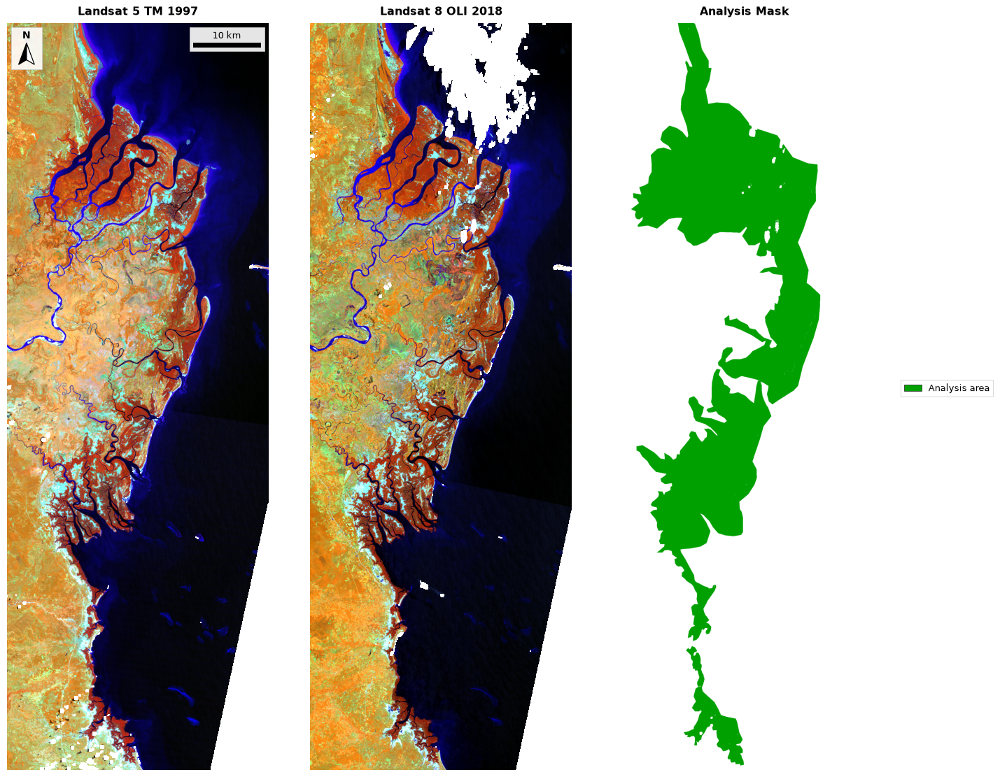

In [5]:
# NIR, SWIR1, red for each sensor, and the mask, side by side.
fig, axs = create_map_panels(
    [
        MapPanel("rgb", input_97_img, bands=[4, 5, 3], title="Landsat 5 TM 1997"),
        MapPanel("rgb", input_18_img, bands=[5, 6, 4], title="Landsat 8 OLI 2018"),
        MapPanel("thematic", anlys_msk_img, title="Analysis Mask"),
    ],
    figsize=(13, 11),
)

## 4. Change Vector Analysis (CVA)

CVA (Malila, 1980) is the simplest multivariate method. For each pixel the difference between the two dates is calculated for every band, giving a *change vector*, and its length (the Euclidean distance) is the change magnitude:

$$d = \sqrt{\sum_{b=1}^{n} (x_b - y_b)^2}$$

where $x_b$ and $y_b$ are the values of band $b$ in the base (1997) and change (2018) images. Unchanged pixels have a small $d$ and changed pixels a large $d$.

**Assumptions:** the two images are radiometrically comparable (the same value means the same thing at both dates) and the bands are on comparable scales. Neither is quite true here: the images come from different sensors and the NIR band has a much larger range than the blue band, so it dominates $d$. Setting `apply_std=True` standardises each band of each image (subtracts the mean and divides by the standard deviation, over the valid pixels) before the difference, which removes overall offsets and gains between the dates and gives each band an equal weight.

**Threshold:** the change distance is split into change / no change using Otsu's threshold (the value which best separates the histogram into two groups) or, with `use_kmeans=True`, a 2-cluster k-means of the distance values (seeded with `rnd_seed`, Default = 42, so the result is the same every run). The output distance image is **centred on the threshold used** for the binary map (i.e., $d$ minus the threshold; `centre_on_threshold=True`, the default for CVA and IR-SFA), so positive values are change and negative values are no change, whichever threshold method is used.

**Outputs:** outside the mask the distance image is no data (`no_data_val`, Default = -9999, which is also set as the file's no-data value). The binary image is a thematic image with a colour table and the class names `No change` (0, grey) and `Change` (1, red), and 255 for no data.

**Diagnostics:** each function returns a dictionary with the threshold (on the distance, before centring), the threshold method, the number of valid pixels analysed and the number labelled change. IR-SFA and IR-MAD also return the number of iterations, whether the iterations converged and their final eigenvalues or canonical correlations.

### 4.1 The Effect of `apply_std` and the Threshold Method

CVA is quick, so first we run it four times to see how much the standardisation and the threshold method change the result.

In [6]:
cva_runs = {}
cva_diags = {}
for apply_std in (False, True):
    for use_kmeans in (False, True):
        tag = f"std{int(apply_std)}_km{int(use_kmeans)}"
        cva_bin_img = os.path.join(out_dir, f"cva_chng_{tag}.tif")
        cva_dist_img = os.path.join(out_dir, f"cva_dist_{tag}.tif")
        cva_diags[tag] = icm.change_vector_analysis(
            input_97_img,
            input_18_img,
            cva_bin_img,
            cva_dist_img,
            vld_msk_img=anlys_msk_img,
            apply_std=apply_std,
            img_base_bands=img_base_bands,
            img_chng_bands=img_chng_bands,
            use_kmeans=use_kmeans,
            use_pbar=False,
        )
        n_chng = cva_diags[tag]["n_change"]
        n_vld = cva_diags[tag]["n_valid"]
        cva_runs[tag] = {
            "apply_std": apply_std,
            "threshold method": cva_diags[tag]["threshold_method"],
            "threshold": round(cva_diags[tag]["threshold"], 3),
            "change (ha)": round(n_chng * pxl_area_ha),
            "change (%)": round(100 * n_chng / n_vld, 1),
        }

pandas.DataFrame(cva_runs).T

,apply_std,threshold method,threshold,change (ha),change (%)
std0_km0,False,otsu,124.003,11396,12.5
std0_km1,False,kmeans,123.924,11407,12.5
std1_km0,True,otsu,2.156,9452,10.4
std1_km1,True,kmeans,2.174,9325,10.2


Standardising the bands reduces the area of change (by about a sixth here): without it the large NIR values (and the overall brightness difference between the two sensors) dominate the distance and make some unchanged pixels look changed. Over the whole scene, rather than just the mangrove habitat, the effect is much larger (try it). Otsu and k-means give almost the same result for CVA. For the rest of the notebook we use the standardised, Otsu thresholded result.

In [7]:
cva_bin_img = os.path.join(out_dir, "cva_chng_std1_km0.tif")
cva_dist_img = os.path.join(out_dir, "cva_dist_std1_km0.tif")
cva_out = cva_diags["std1_km0"]
cva_out

{'threshold': 2.1563384948743867,
 'threshold_method': 'otsu',
 'n_valid': 1014174,
 'n_change': 105022}

### 4.2 Histogram of the CVA Change Distance

`plot_img_histogram` plots the histogram of an image band, here within the analysis mask (`in_msk_img`), and draws thresholds as vertical lines. As the distance is centred on the threshold, the threshold is at 0.

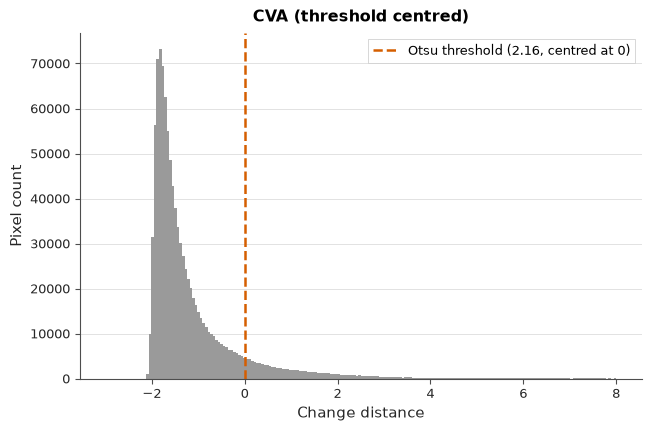

In [8]:
fig, ax = plot_img_histogram(
    cva_dist_img,
    n_bins=200,
    val_range=(-3, 8),
    in_msk_img=anlys_msk_img,
    thresholds=0,
    threshold_labels=f"Otsu threshold ({cva_out['threshold']:.2f}, centred at 0)",
    title="CVA (threshold centred)",
    x_label="Change distance",
    use_pbar=False,
)

### 4.3 Map the CVA Change

`create_map_panels` draws maps side by side with one extent, scale bar and north arrow. The left panel shows the distance with a diverging colour map centred on the threshold (blue = below the threshold, red = above it) and a colour bar; the colour range is set from the 1st and 99th percentiles of the distance within the mask, calculated with `calc_band_percentile_msk`. The right panel shows the binary change over the 2018 image (`base_img`): the change image already has a colour table, and `No change` (0) is drawn transparent so the image shows through. The maps show the subset of the delta used in the other notebooks of this section (`sub_bbox`).

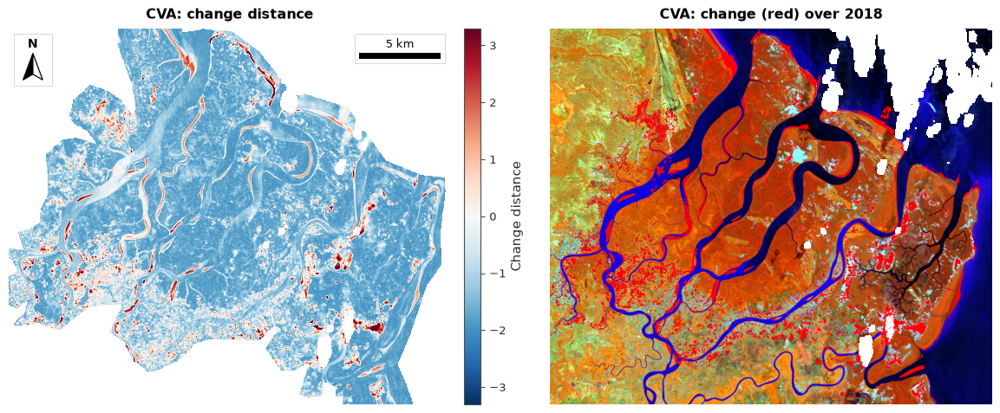

In [9]:
def dist_colour_range(dist_img, centred=True):
    # The 1st and 99th percentiles of a distance within the analysis mask;
    # symmetric about 0 for a threshold-centred distance.
    p_low, p_high = calc_band_percentile_msk(
        dist_img, anlys_msk_img, 1, [1, 99], use_pbar=False
    )[:, 0]
    if centred:
        lim = max(abs(p_low), abs(p_high))
        return -lim, lim
    return p_low, p_high


vmin, vmax = dist_colour_range(cva_dist_img)
fig, axs = create_map_panels(
    [
        MapPanel("cmap", cva_dist_img, cmap_name="RdBu_r", vmin=vmin, vmax=vmax,
                 show_colour_bar=True, cbar_label="Change distance",
                 title="CVA: change distance"),
        MapPanel("thematic", cva_bin_img, base_img=input_18_img, base_bands=[5, 6, 4],
                 in_legend=False, title="CVA: change (red) over 2018"),
    ],
    bbox=sub_bbox,
)

## 5. Iteratively Reweighted Slow Feature Analysis (IR-SFA)

Slow feature analysis looks for the linear combinations of the bands (*features*) which vary the **least** between the two dates, relative to how much they vary across the image. For unchanged pixels these "slow" features should be almost the same at both dates, so a pixel whose features differ is likely to have changed. Wu, Du and Zhang (2014) solve this as a generalised eigenvalue problem: after standardising each band, find the projections $w$ which minimise the variance of the difference $w^T(x - y)$ relative to the variance of $w^T x$ and $w^T y$. The squared differences of all the features, each divided by its variance, are summed to give a **chi-square** distance for every pixel.

The *iterative reweighting* is what makes it work well for change detection: the first estimate uses all the pixels, including the changed ones. Each pixel is then given a weight, its probability of being unchanged (from the chi-square distribution), and the projections are recalculated using those weights. This repeats (up to `sfa_max_iter` iterations, Default = 50) until the eigenvalues stop changing (`sfa_epsilon`). So, the no-change relationship is learnt mainly from the unchanged pixels.

**Assumptions:** most of the pixels are unchanged and the relationship between the two dates for unchanged pixels is linear. As each band is standardised inside the method, differences in gain and offset between the sensors are removed and `apply_std` makes no difference here.

**Threshold:** the output distance is the square root of the chi-square value, centred on its Otsu threshold (as for CVA); `use_kmeans=True` uses k-means instead. `sfa_regular=True` adds a smoothness penalty across the bands and `sfa_norm_trans=True` normalises the transformation; both are off by default.

In [10]:
sfa_bin_img = os.path.join(out_dir, "sfa_chng.tif")
sfa_dist_img = os.path.join(out_dir, "sfa_dist.tif")

sfa_out = icm.slow_feature_analysis(
    input_97_img,
    input_18_img,
    sfa_bin_img,
    sfa_dist_img,
    vld_msk_img=anlys_msk_img,
    img_base_bands=img_base_bands,
    img_chng_bands=img_chng_bands,
    sfa_max_iter=50,
    use_kmeans=False,
    use_pbar=False,
)
print(f"Threshold ({sfa_out['threshold_method']}): {sfa_out['threshold']:.2f}")
print(f"Change: {100 * sfa_out['n_change'] / sfa_out['n_valid']:.1f} % of {sfa_out['n_valid']} pixels")
print(f"Iterations: {sfa_out['n_iter']}, converged: {sfa_out['converged']}")
print("Eigenvalues:", [round(v, 4) for v in sfa_out["eigenvalues"]])

/var/folders/rq/rrjbs1qs2f52j6hv3g0gyvkm0000gq/T/ipykernel_924/25388169.py:4: UserWarning: slow_feature_analysis did not converge in 50 iterations: the last change was 4.84e-05, above sfa_epsilon=1e-06. The reweighting may have locked on to part of the image (one type of land cover), so check the result. Restricting the analysis with a valid mask (vld_msk_img) to areas of comparable land cover usually helps.
  sfa_out = icm.slow_feature_analysis(


Threshold (otsu): 21.81
Change: 12.8 % of 1014174 pixels
Iterations: 50, converged: False
Eigenvalues: [0.0045, 0.0585, 0.1435, 0.2708, 0.5992, 1.0511]


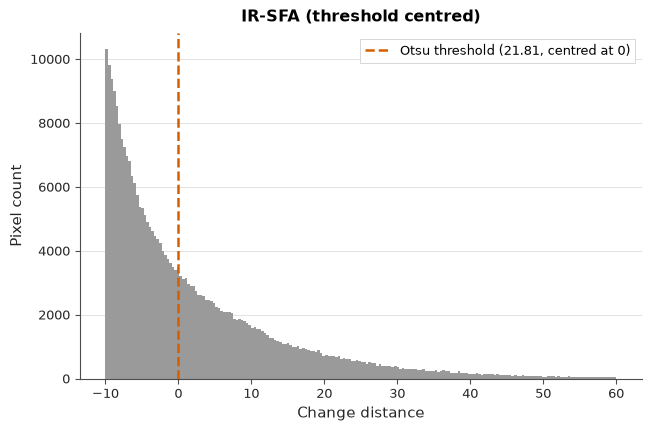

In [11]:
fig, ax = plot_img_histogram(
    sfa_dist_img,
    n_bins=200,
    val_range=(-10, 60),
    in_msk_img=anlys_msk_img,
    thresholds=0,
    threshold_labels=f"Otsu threshold ({sfa_out['threshold']:.2f}, centred at 0)",
    title="IR-SFA (threshold centred)",
    x_label="Change distance",
    use_pbar=False,
)

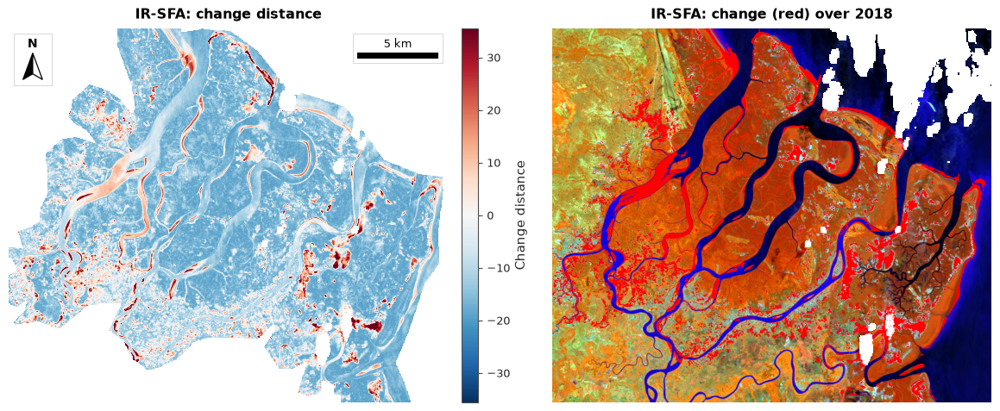

In [12]:
vmin, vmax = dist_colour_range(sfa_dist_img)
fig, axs = create_map_panels(
    [
        MapPanel("cmap", sfa_dist_img, cmap_name="RdBu_r", vmin=vmin, vmax=vmax,
                 show_colour_bar=True, cbar_label="Change distance",
                 title="IR-SFA: change distance"),
        MapPanel("thematic", sfa_bin_img, base_img=input_18_img, base_bands=[5, 6, 4],
                 in_legend=False, title="IR-SFA: change (red) over 2018"),
    ],
    bbox=sub_bbox,
)

## 6. Iteratively Reweighted Multivariate Alteration Detection (IR-MAD)

MAD (Nielsen et al., 1998) uses canonical correlation analysis (CCA): it finds pairs of linear combinations of the bands, $U_i = a_i^T x$ for 1997 and $V_i = b_i^T y$ for 2018, which are as **correlated** as possible. The differences $MAD_i = U_i - V_i$ are the *MAD variates*. Each one is uncorrelated with the others and has a variance of $2(1 - \rho_i)$, where $\rho_i$ is the canonical correlation, so the sum of the squared MAD variates divided by their variances is (for unchanged pixels) approximately chi-square distributed with $n$ (number of bands) degrees of freedom. IR-MAD (Nielsen, 2007) adds the same iterative reweighting as IR-SFA: each pixel is weighted by its chi-square probability of no change, and the CCA is repeated (up to `mad_max_iter` iterations) until the canonical correlations stop changing (`mad_epsilon`).

**Assumptions:** most of the pixels are unchanged and the relationship between the dates for those pixels is linear. A big advantage is that MAD is **invariant to linear transformations** of each image (e.g., a different gain and offset for each band, as between two sensors or two atmospheric corrections), so `apply_std` is not needed.

**Outputs and threshold:** the square root of the chi-square distance (not centred on a threshold by default, unlike CVA and IR-SFA; `centre_on_threshold=True` centres it), the binary change and a multi-band image of the MAD variates. By default (`use_kmeans=True`) the threshold is found with a 2-cluster k-means of the distance; `use_kmeans=False` uses Otsu instead.

In [13]:
mad_bin_img = os.path.join(out_dir, "mad_chng.tif")
mad_dist_img = os.path.join(out_dir, "mad_dist.tif")
mad_vars_img = os.path.join(out_dir, "mad_variates.tif")

mad_out = icm.multivariate_alteration_detection(
    input_97_img,
    input_18_img,
    mad_bin_img,
    mad_dist_img,
    mad_vars_img,
    vld_msk_img=anlys_msk_img,
    img_base_bands=img_base_bands,
    img_chng_bands=img_chng_bands,
    mad_max_iter=50,
    use_kmeans=True,
    use_pbar=False,
)
print(f"Threshold ({mad_out['threshold_method']}): {mad_out['threshold']:.2f}")
print(f"Change: {100 * mad_out['n_change'] / mad_out['n_valid']:.1f} % of {mad_out['n_valid']} pixels")
print(f"Iterations: {mad_out['n_iter']}, converged: {mad_out['converged']}")
print("Canonical correlations:", [round(v, 3) for v in mad_out["canonical_correlations"]])

/var/folders/rq/rrjbs1qs2f52j6hv3g0gyvkm0000gq/T/ipykernel_924/3690465579.py:5: UserWarning: multivariate_alteration_detection did not converge in 50 iterations: the last change was 3.12e-06, above mad_epsilon=1e-06. The reweighting may have locked on to part of the image (one type of land cover), so check the result. Restricting the analysis with a valid mask (vld_msk_img) to areas of comparable land cover usually helps.
  mad_out = icm.multivariate_alteration_detection(


Threshold (kmeans): 24.39
Change: 16.4 % of 1014174 pixels
Iterations: 50, converged: False
Canonical correlations: [0.588, 0.706, 0.85, 0.927, 0.968, 0.998]


**Convergence:** both IR-SFA and IR-MAD gave a warning that they had not converged in 50 iterations. The diagnostics show how far they were from it: the last change in the IR-MAD canonical correlations was about 3e-6 (against `mad_epsilon=1e-6`) and in the IR-SFA eigenvalues about 5e-5 (against `sfa_epsilon=1e-6`), so within the mangrove habitat the weights had settled and the results would barely change with more iterations (raise `mad_max_iter` / `sfa_max_iter`, or loosen the epsilon, to check). A warning with a large last change, as in section 9, is the one to worry about.

### 6.1 The MAD Variates

In the rsgispy output, band 1 of the MAD variates image comes from the pair of features with the **lowest** canonical correlation and has the largest variance, so the first MAD variates hold most of the change; the last ones mainly hold noise. Values near 0 are no change, and the sign shows the direction of the change in that feature. Below, the first three MAD variates are shown as an RGB composite and each variate is mapped separately.

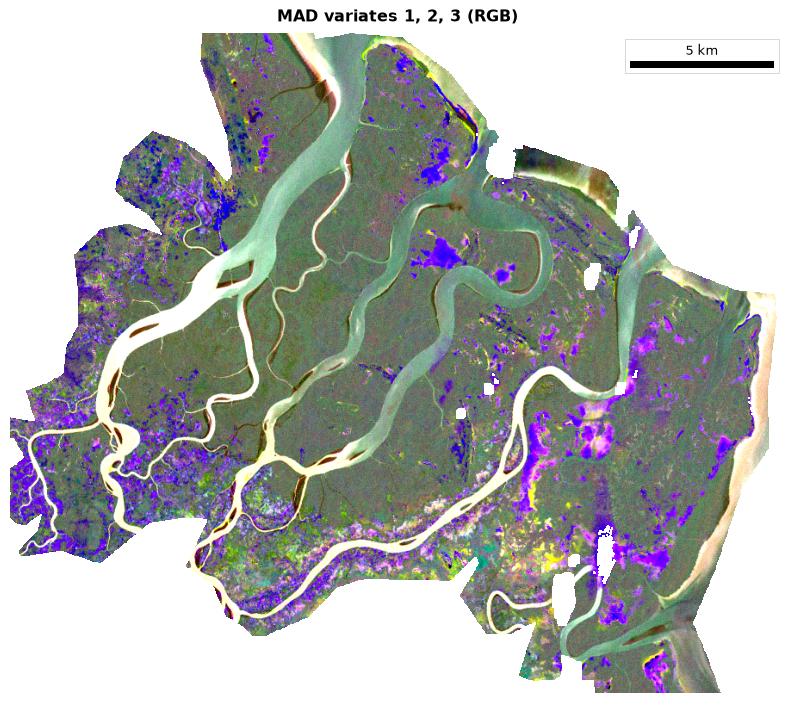

In [14]:
fig, ax = plt.subplots(figsize=(10, 9))
img = create_raster_img_map(
    ax,
    mad_vars_img,
    img_bands=[1, 2, 3],
    img_stch=rsgispy.IMG_STRETCH_STDEV,
    bbox=sub_bbox,
    title_str="MAD variates 1, 2, 3 (RGB)",
    show_scale_bar=True,
    show_map_axis=False,
)

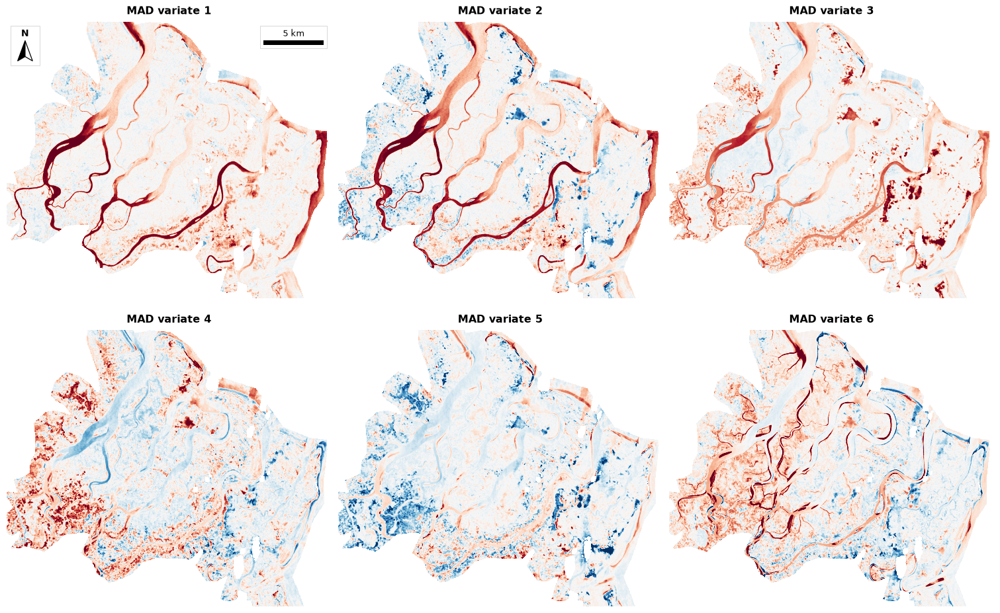

In [15]:
# The 1st and 99th percentiles of each MAD variate within the mask
# (an array with one row per percentile and one column per band).
mad_pcts = calc_band_percentile_msk(mad_vars_img, anlys_msk_img, 1, [1, 99], use_pbar=False)

panels = []
for i in range(len(img_base_bands)):
    lim = max(abs(mad_pcts[0, i]), abs(mad_pcts[1, i]))
    panels.append(
        MapPanel("cmap", mad_vars_img, bands=i + 1, cmap_name="RdBu_r", vmin=-lim,
                 vmax=lim, title=f"MAD variate {i + 1}")
    )
fig, axs = create_map_panels(panels, ncols=3, bbox=sub_bbox)

### 6.2 Map the IR-MAD Change

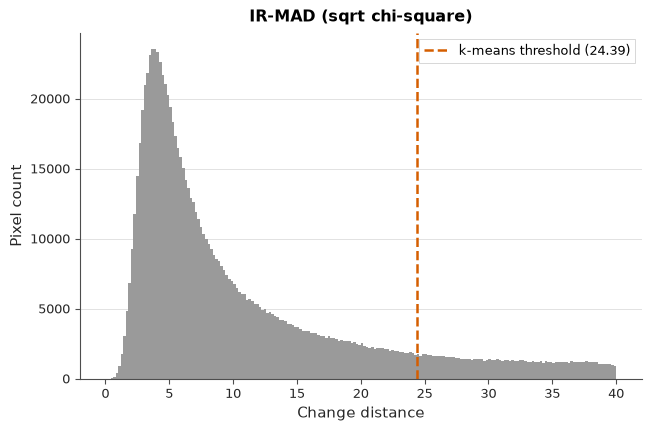

In [16]:
fig, ax = plot_img_histogram(
    mad_dist_img,
    n_bins=200,
    val_range=(0, 40),
    in_msk_img=anlys_msk_img,
    thresholds=mad_out["threshold"],
    threshold_labels=f"k-means threshold ({mad_out['threshold']:.2f})",
    title="IR-MAD (sqrt chi-square)",
    x_label="Change distance",
    use_pbar=False,
)

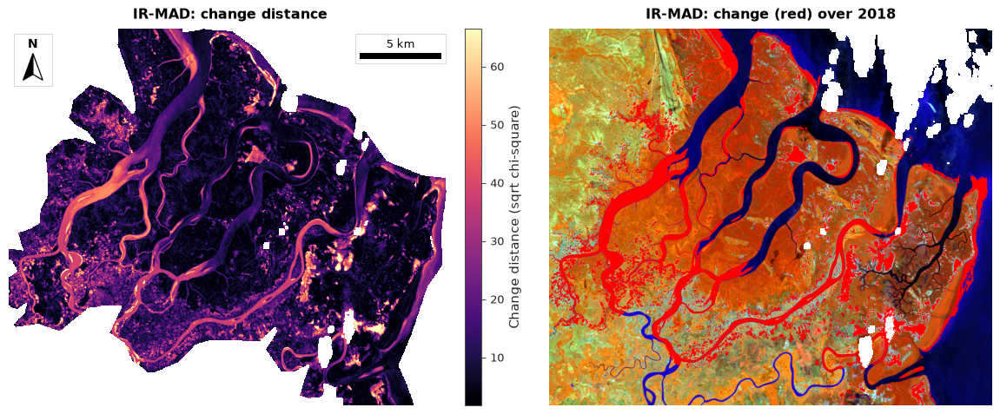

In [17]:
vmin, vmax = dist_colour_range(mad_dist_img, centred=False)
fig, axs = create_map_panels(
    [
        MapPanel("cmap", mad_dist_img, cmap_name="magma", vmin=vmin, vmax=vmax,
                 show_colour_bar=True, cbar_label="Change distance (sqrt chi-square)",
                 title="IR-MAD: change distance"),
        MapPanel("thematic", mad_bin_img, base_img=input_18_img, base_bands=[5, 6, 4],
                 in_legend=False, title="IR-MAD: change (red) over 2018"),
    ],
    bbox=sub_bbox,
)

### 6.3 A Chi-Square Threshold

As the IR-MAD distance is (for unchanged pixels) the square root of a chi-square variable with 6 degrees of freedom, we can also set the threshold from a probability of no change instead of k-means or Otsu, as Nielsen (2007) suggests. For example, pixels with less than a 1 % chance of being unchanged have a chi-square value above the 99th percentile of the chi-square distribution. The threshold is calculated with `scipy.stats.chi2.ppf` and applied with `band_maths`.

In practice, the chi-square assumption only holds approximately: neighbouring pixels are correlated, and the reweighting fits the no-change relationship most closely to the most stable pixels (here the dense mangroves), so the other unchanged pixels have larger distances than the chi-square distribution predicts. You can see this in the histogram in section 6.2: its peak is near 4, while for 6 bands it should be near 2.2. So, on this data the chi-square threshold flags most of the habitat as change, far more than k-means. Treat the k-means (or Otsu) threshold as a starting point, and check the result against what you know about the area.

In [18]:
n_bands = len(img_base_bands)
chi2_thres = scipy.stats.chi2.ppf(0.99, n_bands) ** 0.5
print(f"sqrt(chi-square) threshold (p = 0.99, {n_bands} bands): {chi2_thres:.2f}")

mad_chi2_bin_img = os.path.join(out_dir, "mad_chng_chi2_p99.tif")
band_defns = [
    BandDefn("msk", anlys_msk_img, 1),
    BandDefn("dist", mad_dist_img, 1),
]
band_maths(
    mad_chi2_bin_img,
    f"(msk==1)?(dist>{chi2_thres}):255",
    band_defns,
    datatype=rsgispy.TYPE_8UINT,
    no_data_val=255,
    use_pbar=False,
)
# A thematic image with the same class names as the other change maps
# (0 is a class here, so ignore_zero=False; 255 is the no-data value).
set_thematic_classes(
    mad_chi2_bin_img,
    {0: ("No change", (200, 200, 200)), 1: ("Change", (255, 140, 0))},
    ignore_zero=False,
)

for name, img in (("k-means", mad_bin_img), ("chi-square p=0.99", mad_chi2_bin_img)):
    n_no_chng, n_chng = count_pxls_of_val(img, [0, 1], img_band=1, use_pbar=False)
    print(f"IR-MAD {name:>18}: {n_chng * pxl_area_ha:8.0f} ha ({100 * n_chng / (n_chng + n_no_chng):.1f} %)")

sqrt(chi-square) threshold (p = 0.99, 6 bands): 4.10
IR-MAD            k-means:    14975 ha (16.4 %)
IR-MAD  chi-square p=0.99:    72016 ha (78.9 %)


## 7. Compare the Three Methods

### 7.1 Change Area

The diagnostics returned by each function give the number of valid pixels and of change pixels, and the threshold used.

In [19]:
chng_imgs = {
    "CVA": cva_bin_img,
    "IR-SFA": sfa_bin_img,
    "IR-MAD": mad_bin_img,
}
chng_diags = {"CVA": cva_out, "IR-SFA": sfa_out, "IR-MAD": mad_out}

chng_areas = {}
for name, diag in chng_diags.items():
    n_chng, n_vld = diag["n_change"], diag["n_valid"]
    chng_areas[name] = {
        "threshold": f"{diag['threshold']:.2f} ({diag['threshold_method']})",
        "change (ha)": round(n_chng * pxl_area_ha),
        "no change (ha)": round((n_vld - n_chng) * pxl_area_ha),
        "change (%)": round(100 * n_chng / n_vld, 1),
    }
pandas.DataFrame(chng_areas).T

,threshold,change (ha),no change (ha),change (%)
CVA,2.16 (otsu),9452,81824,10.4
IR-SFA,21.81 (otsu),11713,79563,12.8
IR-MAD,24.39 (kmeans),14975,76301,16.4


### 7.2 Where Do the Methods Agree?

`band_maths` combines the three binary maps into one image where each combination of results has its own value (1 + CVA + 2 × IR-SFA + 4 × IR-MAD), so 1 is no change in all three methods and 8 is change in all three.

In [20]:
agree_img = os.path.join(out_dir, "chng_agreement.tif")
band_defns = [
    BandDefn("msk", anlys_msk_img, 1),
    BandDefn("cva", cva_bin_img, 1),
    BandDefn("sfa", sfa_bin_img, 1),
    BandDefn("mad", mad_bin_img, 1),
]
band_maths(
    agree_img,
    "(msk==1)?(1 + cva + 2*sfa + 4*mad):0",
    band_defns,
    datatype=rsgispy.TYPE_8UINT,
    use_pbar=False,
)

# pixel value: (name, (red, green, blue))
agree_cls_info = {
    1: ("No change (all)", (230, 230, 230)),
    2: ("CVA only", (255, 220, 0)),
    3: ("IR-SFA only", (0, 200, 255)),
    4: ("CVA + IR-SFA", (0, 160, 0)),
    5: ("IR-MAD only", (200, 0, 255)),
    6: ("CVA + IR-MAD", (255, 120, 0)),
    7: ("IR-SFA + IR-MAD", (0, 0, 200)),
    8: ("Change (all)", (200, 0, 0)),
}
set_thematic_classes(agree_img, agree_cls_info)
agree_cls_names = {val: name for val, (name, _) in agree_cls_info.items()}

agree_counts = count_pxls_of_val(agree_img, list(agree_cls_names), img_band=1, use_pbar=False)
agree_df = pandas.DataFrame(
    {
        "area (ha)": (agree_counts * pxl_area_ha).round(0),
        "area (%)": (100 * agree_counts / agree_counts.sum()).round(1),
    },
    index=list(agree_cls_names.values()),
)
agree_df

,area (ha),area (%)
No change (all),74672.0,81.8
CVA only,976.0,1.1
IR-SFA only,308.0,0.3
CVA + IR-SFA,345.0,0.4
IR-MAD only,3708.0,4.1
CVA + IR-MAD,207.0,0.2
IR-SFA + IR-MAD,3136.0,3.4
Change (all),7924.0,8.7


From the same counts we can calculate how often each pair of methods gives the same answer (both change or both no change) and how many of the pixels flagged as change by one method are also flagged by the other.

In [21]:
# Counts indexed by the (cva, sfa, mad) result of each combination.
cnt = {
    (cva, sfa, mad): agree_counts[cva + 2 * sfa + 4 * mad]
    for cva in (0, 1)
    for sfa in (0, 1)
    for mad in (0, 1)
}
n_tot = agree_counts.sum()
methods = ["CVA", "IR-SFA", "IR-MAD"]

pair_stats = {}
for i in range(3):
    for j in range(i + 1, 3):
        same = sum(c for key, c in cnt.items() if key[i] == key[j])
        both = sum(c for key, c in cnt.items() if key[i] == 1 and key[j] == 1)
        either = sum(c for key, c in cnt.items() if key[i] == 1 or key[j] == 1)
        pair_stats[f"{methods[i]} vs {methods[j]}"] = {
            "same result (%)": round(100 * same / n_tot, 1),
            "change in both / change in either (%)": round(100 * both / either, 1),
        }
pandas.DataFrame(pair_stats).T

,same result (%),change in both / change in either (%)
CVA vs IR-SFA,94.9,64.1
CVA vs IR-MAD,91.1,49.9
IR-SFA vs IR-MAD,95.0,70.8


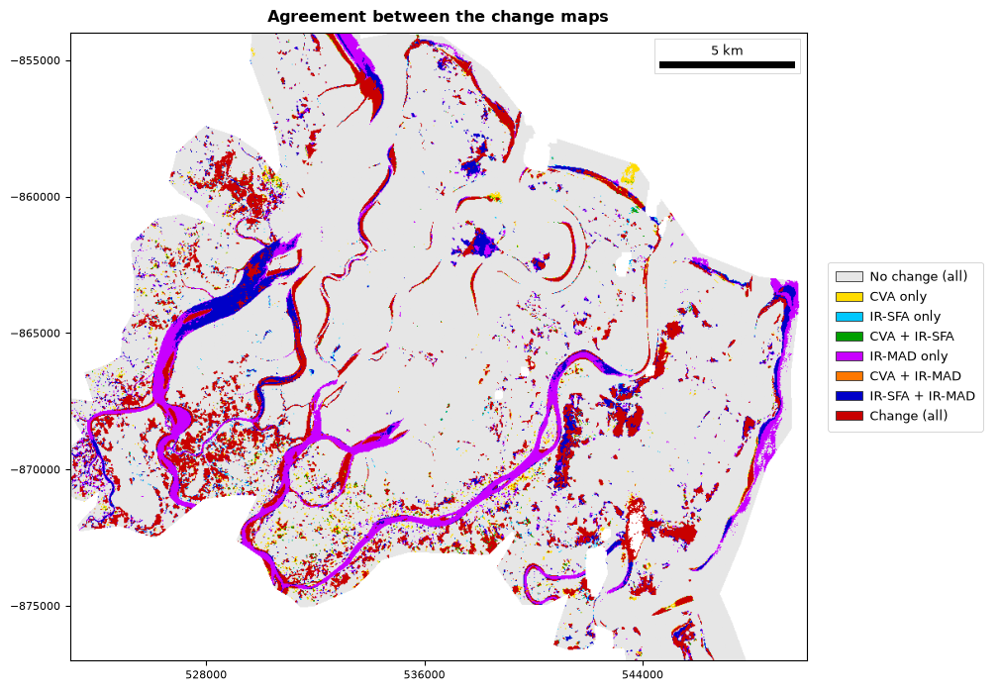

In [22]:
fig, ax = plt.subplots(figsize=(12, 10))
# The legend uses the class names stored in the image.
img = create_thematic_raster_map(
    ax,
    agree_img,
    bbox=sub_bbox,
    title_str="Agreement between the change maps",
    show_legend=True,
    legend_ncols=1,
)

### 7.3 Side-by-Side Comparison

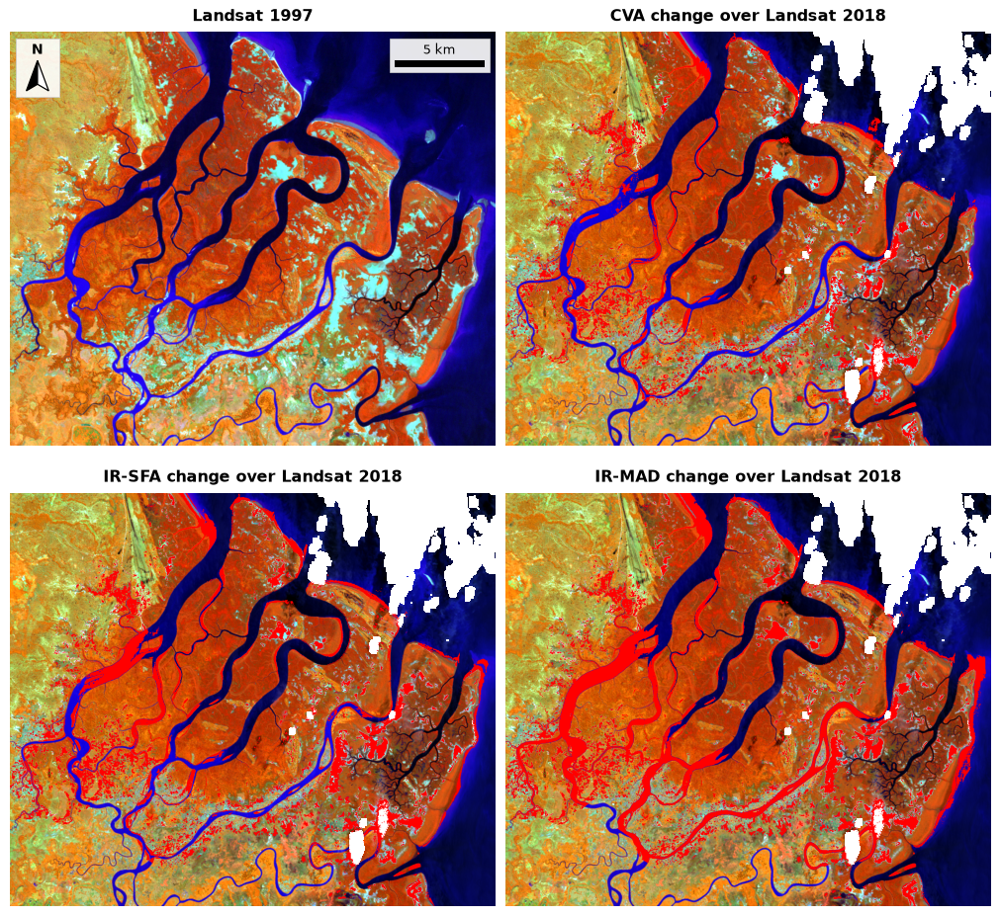

In [23]:
fig, axs = create_map_panels(
    [MapPanel("rgb", input_97_img, bands=[4, 5, 3], title="Landsat 1997")]
    + [
        MapPanel("thematic", img, base_img=input_18_img, base_bands=[5, 6, 4],
                 in_legend=False, title=f"{name} change over Landsat 2018")
        for name, img in chng_imgs.items()
    ],
    ncols=2,
    bbox=sub_bbox,
    out_plot_file=os.path.join(out_dir, "multivariate_chng_comparison.png"),
    out_dpi=100,
)

## 8. Compare with the Map-to-Map Change

The map-to-map change map from `02_map_to_map_change` gives, for each pixel, the 1997 and 2018 classes. It has its own errors, but it lets us ask which kinds of change each method detects: for each from–to class we calculate the percentage of its pixels within the analysis mask which each method flagged as change. The class names are read from the change map with `get_thematic_classes` (notebook 02 stored them with `set_thematic_classes`), the images are read into arrays with `get_img_data_as_arr` and summarised with pandas. This cell is skipped if notebook 02 has not been run.

In [24]:
map_to_map_chg_img = os.path.join("outputs", "map_to_map_chg", "chng_map_1997_2018_img.tif")

if os.path.exists(map_to_map_chg_img):
    chng_cls_names = {
        val: name for val, (name, _) in get_thematic_classes(map_to_map_chg_img).items()
    }
    msk_arr = get_img_data_as_arr(anlys_msk_img)[0] == 1
    pxls_df = pandas.DataFrame(
        {"map_to_map": get_img_data_as_arr(map_to_map_chg_img)[0][msk_arr]}
    )
    for name, img in chng_imgs.items():
        pxls_df[name] = get_img_data_as_arr(img)[0][msk_arr] == 1
    pxls_df = pxls_df[pxls_df["map_to_map"].isin(list(chng_cls_names))]
    pxls_df["map_to_map"] = pxls_df["map_to_map"].map(chng_cls_names)

    cmp_df = (100 * pxls_df.groupby("map_to_map")[list(chng_imgs)].mean()).round(1)
    cmp_df.insert(0, "area (ha)", (pxls_df.groupby("map_to_map").size() * pxl_area_ha).round(0))
    display(cmp_df)
else:
    print("Run 01_create_baseline_class and 02_map_to_map_change for this comparison.")

,area (ha),CVA,IR-SFA,IR-MAD
map_to_map,,,,
Mangrove_Mangrove,32501.0,0.5,0.5,0.4
Mangrove_Terrestrial,4090.0,28.5,32.9,32.4
Mangrove_Water,684.0,16.8,23.2,24.7
Terrestrial_Mangrove,4439.0,9.8,8.4,6.8
Terrestrial_Terrestrial,30302.0,18.6,23.9,28.0
Terrestrial_Water,645.0,76.7,89.5,89.6
Water_Mangrove,746.0,70.8,72.2,69.7
Water_Terrestrial,1690.0,17.1,21.7,65.5
Water_Water,16180.0,3.9,5.8,14.7


The pixels which are the same class in both classifications (e.g., `Mangrove_Mangrove`, `Water_Water`) should mostly be no change, and the changed classes (e.g., `Mangrove_Water`, `Water_Mangrove`) should mostly be change. Almost none of the stable mangroves (`Mangrove_Mangrove`) are flagged, and all three methods detect most of the water to mangrove change (mangroves colonising new mud banks) and the terrestrial to water change. Only about a third of the mangrove loss (`Mangrove_Terrestrial`) is detected, and a fifth to a quarter of the stable terrestrial area is flagged as change: the land behind the mangroves (farmland, grass and bare ground) can change a lot spectrally (crops, soil moisture, burning) without changing class. IR-MAD flags far more of the stable water than the other methods: these are the river channels, whose sediment load (and so reflectance) differs between the dates. Some of the disagreement will also be errors in the two classifications rather than in the change detection.

## 9. What Happens Without the Habitat Mask?

To see why the habitat mask was used, IR-MAD is run again for every pixel which is valid in both images (the mask from section 3.1).

In [25]:
mad_all_bin_img = os.path.join(out_dir, "mad_chng_all_pxls.tif")
mad_all_dist_img = os.path.join(out_dir, "mad_dist_all_pxls.tif")
mad_all_vars_img = os.path.join(out_dir, "mad_variates_all_pxls.tif")

mad_all_out = icm.multivariate_alteration_detection(
    input_97_img,
    input_18_img,
    mad_all_bin_img,
    mad_all_dist_img,
    mad_all_vars_img,
    vld_msk_img=vld_msk_img,
    img_base_bands=img_base_bands,
    img_chng_bands=img_chng_bands,
    use_pbar=False,
)
print(f"IR-MAD, all valid pixels: {100 * mad_all_out['n_change'] / mad_all_out['n_valid']:.1f} % change")
print(f"Threshold ({mad_all_out['threshold_method']}): {mad_all_out['threshold']:.1f}")
print(f"Iterations: {mad_all_out['n_iter']}, converged: {mad_all_out['converged']}, "
      f"last change in the canonical correlations: {mad_all_out['last_change']:.4f}")
print("Canonical correlations:", [round(v, 3) for v in mad_all_out["canonical_correlations"]])

/var/folders/rq/rrjbs1qs2f52j6hv3g0gyvkm0000gq/T/ipykernel_924/3410658443.py:5: UserWarning: multivariate_alteration_detection did not converge in 50 iterations: the last change was 0.0586, above mad_epsilon=1e-06. The reweighting may have locked on to part of the image (one type of land cover), so check the result. Restricting the analysis with a valid mask (vld_msk_img) to areas of comparable land cover usually helps.
  mad_all_out = icm.multivariate_alteration_detection(


IR-MAD, all valid pixels: 49.8 % change
Threshold (kmeans): 337.1
Iterations: 50, converged: False, last change in the canonical correlations: 0.0586
Canonical correlations: [0.439, 0.511, 0.632, 0.859, 0.978, 0.984]


### 9.1 Regularised IR-MAD

`mad_regularisation` adds a ridge term ($\lambda$ times the mean band variance of each date) to the covariance matrices of the canonical correlation analysis (Nielsen, 2007). It stabilises the analysis when the bands are (nearly) collinear, as they are for the few pixels the weights have concentrated on, and keeps the canonical correlations below 1. Below, the whole-scene IR-MAD is run again with $\lambda = 0.01$.

In [26]:
mad_all_reg_bin_img = os.path.join(out_dir, "mad_chng_all_pxls_reg.tif")
mad_all_reg_dist_img = os.path.join(out_dir, "mad_dist_all_pxls_reg.tif")
mad_all_reg_vars_img = os.path.join(out_dir, "mad_variates_all_pxls_reg.tif")

mad_all_reg_out = icm.multivariate_alteration_detection(
    input_97_img,
    input_18_img,
    mad_all_reg_bin_img,
    mad_all_reg_dist_img,
    mad_all_reg_vars_img,
    vld_msk_img=vld_msk_img,
    img_base_bands=img_base_bands,
    img_chng_bands=img_chng_bands,
    mad_regularisation=0.01,
    use_pbar=False,
)
print(f"Regularised IR-MAD (0.01), all valid pixels: "
      f"{100 * mad_all_reg_out['n_change'] / mad_all_reg_out['n_valid']:.1f} % change")
print(f"Threshold ({mad_all_reg_out['threshold_method']}): {mad_all_reg_out['threshold']:.1f}")
print(f"Iterations: {mad_all_reg_out['n_iter']}, converged: {mad_all_reg_out['converged']}, "
      f"last change in the canonical correlations: {mad_all_reg_out['last_change']:.4f}")
print("Canonical correlations:", [round(v, 3) for v in mad_all_reg_out["canonical_correlations"]])

/var/folders/rq/rrjbs1qs2f52j6hv3g0gyvkm0000gq/T/ipykernel_924/3730844442.py:5: UserWarning: multivariate_alteration_detection did not converge in 50 iterations: the last change was 0.00212, above mad_epsilon=1e-06. The reweighting may have locked on to part of the image (one type of land cover), so check the result. Restricting the analysis with a valid mask (vld_msk_img) to areas of comparable land cover usually helps.
  mad_all_reg_out = icm.multivariate_alteration_detection(


Regularised IR-MAD (0.01), all valid pixels: 18.5 % change
Threshold (kmeans): 58.5
Iterations: 50, converged: False, last change in the canonical correlations: 0.0021
Canonical correlations: [0.119, 0.582, 0.795, 0.935, 0.982, 0.996]


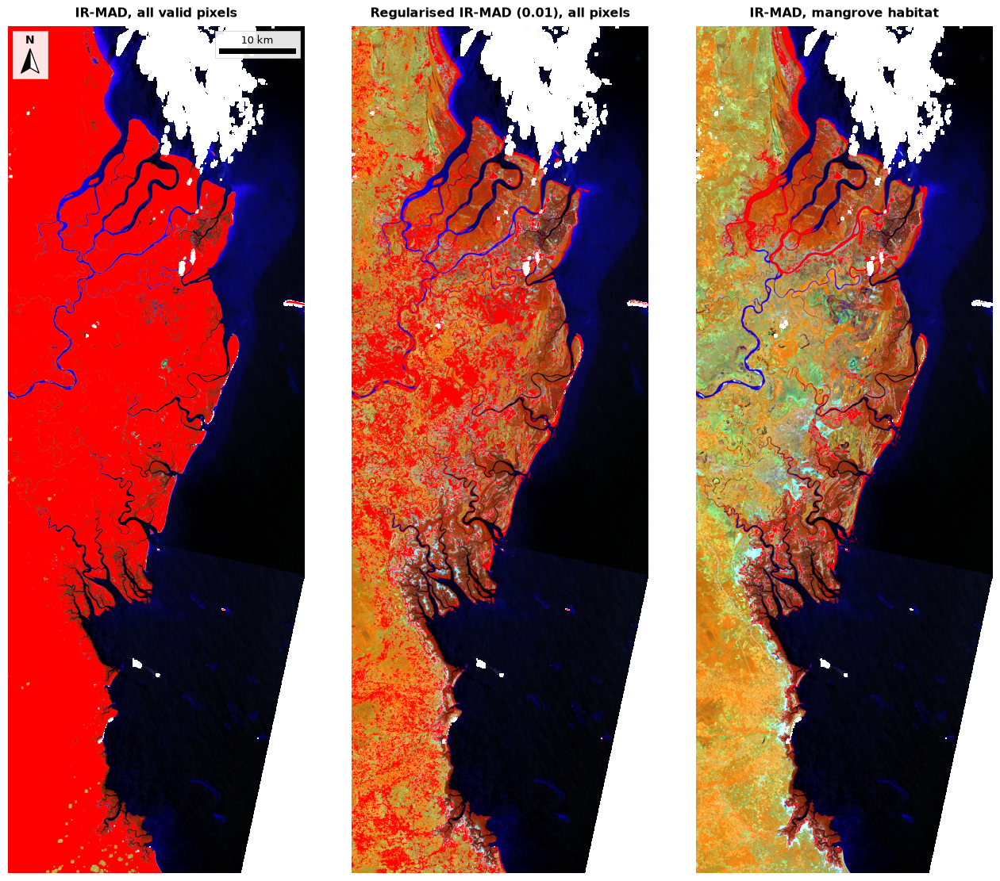

In [27]:
fig, axs = create_map_panels(
    [
        MapPanel("thematic", img, base_img=input_18_img, base_bands=[5, 6, 4],
                 in_legend=False, title=title)
        for img, title in (
            (mad_all_bin_img, "IR-MAD, all valid pixels"),
            (mad_all_reg_bin_img, "Regularised IR-MAD (0.01), all pixels"),
            (mad_bin_img, "IR-MAD, mangrove habitat"),
        )
    ],
    figsize=(13, 11),
)

Across the whole scene, IR-MAD labels about half of the pixels as change, including most of the dry land, and the diagnostics show that something has gone wrong: the iterations did not converge (the canonical correlations were still changing by about 0.06 after 50 iterations) and the k-means threshold on the distance is about 337, against about 24 within the mangrove habitat. The reweighting has "locked on" to one part of the scene: after the first iteration the pixels with a low chi-square (mostly water) get the highest weights, the next canonical correlation analysis then fits the no-change relationship for those pixels only, everything else looks even more different, and the weights concentrate on fewer and fewer pixels. The method is working as designed; its assumption that the **unchanged pixels share one linear relationship between the dates** is not true for a scene this varied, 21 years apart and with two different sensors.

Regularisation (`mad_regularisation=0.01`) reduces the collapse, from 49.8 % to about 18 % change, as the ridge term stops the analysis fitting the few heavily weighted pixels exactly. It does not stop it: the iterations still do not converge, large parts of the farmland inland are still flagged as change (middle map), and the first canonical correlation falls to about 0.1, i.e. the first MAD variate no longer describes a relationship shared by the two dates. The regularisation treats the symptom (an ill-conditioned covariance matrix) and not the cause (one linear no-change relationship cannot fit water, mangroves and farmland at once). Restricting the analysis to areas of comparable land cover (as we did with the habitat mask) is still needed to make the assumption reasonable. You can also limit the iterations: `mad_max_iter=1` gives the original (not reweighted) MAD.

## Observations of the Results

- **CVA** is the fastest and simplest, but needs the images to be radiometrically comparable. Standardising the bands (`apply_std=True`) reduced the area of change by about a sixth here, and matters much more over the whole scene.
- **IR-SFA** and **IR-MAD** learn the no-change relationship between the dates from the data, so differences in gain and offset between the sensors do not matter. They give a chi-square distance which has a statistical meaning (the probability of no change), but they are slower and depend on most of the analysed area being unchanged. Check the diagnostics they return (`converged`, `last_change`, `threshold`): a run which has not converged, with a large last change, has probably locked on to one land cover.
- Within the mangrove habitat the three methods agree for 91 – 95 % of the pixels and find the same main changes (new mangroves on accreting mud banks, losses along the channels and changes in the land behind the mangroves). The biggest difference is that IR-MAD also flags the river channels, where the change is in the water (sediment) rather than the land cover. A spectral change is not always the change you are interested in.
- The threshold method (Otsu, k-means or chi-square) can change the area of change as much as, or more than, the choice of method, so it is worth checking a few thresholds against your knowledge of the area.
- None of the methods tell you *what* the change is: combining a binary change map with a classification (as in notebooks 03 and 04) is the next step to a from–to change map.

## Things to Try

1. Run IR-SFA and IR-MAD with `use_kmeans` switched (Otsu vs k-means) and compare the areas of change with the table in section 7.1.
2. Run CVA with `apply_std=False` but using only the NIR and SWIR bands (e.g., `img_base_bands=[4, 5, 6]`, `img_chng_bands=[5, 6, 7]`). How does the change differ from using all six bands?
3. Try `sfa_regular=True` for IR-SFA, and `mad_max_iter=1` (plain MAD) for IR-MAD. How much difference does the reweighting make within the mangrove habitat?
4. Run CVA and IR-SFA for all valid pixels (the `vld_msk_img` mask) and compare with the result of section 9.
5. Try other values of `mad_regularisation` (e.g., 0.001 and 0.1) for the whole scene, and within the mangrove habitat. Look at the canonical correlations and the change maps, not only the area of change.
6. Use the change distance rather than the binary map: e.g., threshold the IR-MAD distance at several chi-square probabilities (0.95, 0.99, 0.999) with `band_maths` and see where the extra change pixels are.
7. Update the 1997 classification from `01_create_baseline_class` using the IR-MAD change map: pixels with no change keep their 1997 class and the changed pixels are classified with the 2018 classifier from `02_map_to_map_change`.

## References

- Malila, W.A. (1980). Change vector analysis: an approach for detecting forest changes with Landsat. *LARS Symposia*, Paper 385, Purdue University.
- Nielsen, A.A., Conradsen, K. and Simpson, J.J. (1998). Multivariate alteration detection (MAD) and MAF postprocessing in multispectral, bitemporal image data: new approaches to change detection studies. *Remote Sensing of Environment*, 64(1), 1–19.
- Nielsen, A.A. (2007). The regularized iteratively reweighted MAD method for change detection in multi- and hyperspectral data. *IEEE Transactions on Image Processing*, 16(2), 463–478.
- Wu, C., Du, B. and Zhang, L. (2014). Slow feature analysis for change detection in multispectral imagery. *IEEE Transactions on Geoscience and Remote Sensing*, 52(5), 2858–2874.